<a href="https://colab.research.google.com/github/erickcorrea3092/AZH_ACE_QSARMODEL/blob/main/2_AZH_similitud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANTECEDENTES

Primero instalamos la libreria RDKit

In [1]:
! pip install dash==3.2.0

In [2]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install molplotly
      !pip install rdkit
      !pip install molplotly     #__________________
      import pandas as pd
      import numpy as np
      import seaborn as sn
      #---------------------- RDKit packages
      import molplotly
      from rdkit.Chem import AllChem
      from rdkit.Chem import rdMolDescriptors
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import Draw
      from rdkit import DataStructs
      from rdkit.ML.Cluster import Butina
      from rdkit.Chem import PandasTools
      from rdkit import Chem
      from rdkit.Chem import rdFMCS
      #---------------------- plotly packages
      import plotly.express as px
      import molplotly
      import matplotlib.pyplot as plt
      #from tqdm import tqdm.notebook
      #------------------- hide warning
      import warnings
      warnings.filterwarnings('ignore')
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

#Cargamos datos

In [3]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      #Cargamos las datos de una dirección de git hub
      #! gdown --id 1cHM9neEhTOZ82UU9HaZkdGdlwE1d4SJT
      #dataset = pd.read_excel('data.xlsx')
      ! gdown --id 1IGJnrENv9Oq-E8IwMdp81SVpsDEPoIkW
      dataset = pd.read_excel("AZH.xlsx")
      dataset.shape #vemos los primeros diez datos
      #! gdown --id 1wZp9pou63ElEYyGGjBeC2pDtscgRgCpj#1Uy
      df_y = dataset['pChEMBL Value']
      #dataset = dataset.assign(Activity=df_y)
      #dataset['Activity'] = dataset['Activity'].round(2)
      pbar.update(100)



  0%|          | 0/100 [00:00<?, ?it/s]

In [4]:
# prompt: borra la primera y la tres últimas columans de dataset
eliminar = True
if eliminar is True:
  # Eliminamos la primera columna por nombre
  dataset = dataset.drop(columns=[dataset.columns[0]])
  # Eliminamos las tres últimas columnas por índice
  dataset = dataset.drop(columns=dataset.columns[-3:])


# Mostrar la nueva forma del dataset
print(dataset.shape)
dataset.head()

(5829, 14)


,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,Structure,Molecule ChEMBL ID,pChEMBL Value,Molecule Name
0,0.795789,243.350,2.77350,18,2,20.31,2,0,1,CN1CCC(CC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7bed5187f4c0>,CHEMBL345905,8.11,NaN
1,0.834365,271.404,3.55370,20,4,20.31,2,0,1,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7bed5187e5e0>,CHEMBL263322,8.82,NaN
2,0.422541,208.281,2.11702,15,2,26.30,2,0,0,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1,<rdkit.Chem.rdchem.Mol object at 0x7bed5187df50>,CHEMBL338492,5.27,NaN
3,0.603594,405.542,4.50920,30,6,41.74,5,0,1,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1,<rdkit.Chem.rdchem.Mol object at 0x7bed5187e7a0>,CHEMBL93936,9.10,NaN
4,0.805692,236.267,2.08730,17,3,44.76,4,0,1,COc1cc2c(c(OC)c1OC)C(=O)C(C)C2,<rdkit.Chem.rdchem.Mol object at 0x7bed5187e810>,CHEMBL440185,7.88,NaN


#Funciones

In [5]:
def find_mcs_multiple(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]

    # Check for invalid SMILES
    if any(mol is None for mol in mols):
        print("Invalid SMILES string provided in the list.")
        return None, None, 0, False

    mcs = rdFMCS.FindMCS(mols)
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)

    return mcs_mol, mcs.smartsString, mcs.numAtoms, True

In [6]:
def draw_multiple_mcs(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]
    mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(filtered_df.SMILES)
    if success:
        highlight_lists = [mol.GetSubstructMatch(mcs_mol) for mol in mols]

        # Get pIC50 values from the original df using indices from filtered_df
        pic50_values = [filtered_df.loc[idx, 'pChEMBL Value'] for idx in filtered_df.index]

        mols.append(mcs_mol)  # Add MCS to list for drawing
        highlight_lists.append([]) # No highlight for MCS itself

        # Create legends with pIC50 values
        legends = [f"pIC50: {pic50:.2f}, cluster: {cluster_number} " for pic50 in pic50_values]
        legends.append(f"MCS cluster: {cluster_number}") # Legend for MCS

        img = Draw.MolsToGridImage(mols,
                                   legends=legends,
                                   highlightAtomLists=highlight_lists,
                                   subImgSize=(450,450))
        return img
    else:
        return None

In [7]:
#regresa el MCS entre dos moléculas
def find_mcs_and_draw(mol1, mol2):
    mcs = rdFMCS.FindMCS([mol1, mol2])
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)
    if mcs_mol:
        # generacion de la imagen
        img = Draw.MolsToGridImage([mol1, mol2, mcs_mol],
                                    #legends=['m', 'a', 'MCS'],
                                   legends=[#'Cluster ID: ' + str(x) +
                                            ', pIC50: ' + str(y) +
                                            ', index: '+ str(z)
                                            for y, z in zip(#dataset.Cluster_number,
                                                               dataset['pChEMBL Value'],
                                                               dataset['Molecule ChEMBL ID'])],

                                    highlightAtomLists=[
                                        mol1.GetSubstructMatch(mcs_mol),
                                        mol2.GetSubstructMatch(mcs_mol),
                                        [] # No highlighting for the MCS itself
                                    ])
        return img
    else:
        return None

In [8]:
#df_y = pd.read_excel("Actividad.xlsx")
#dataset = dataset.assign(Activity=df_y)
#dataset['Activity'] = dataset['Activity'].round(2)
#dataset

In [9]:
# Incluyamos estructuras 2D  de las moleculas para conocer los datos
# https://github.com/rdkit/rdkit/blob/master/rdkit/Chem/PandasTools.py

from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')

# Agrupación de Taylor-Butina (Taylor-Butina Clustering)

In [10]:
#función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # generate distance matrix:
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):

        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])

    # cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [11]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in dataset.Structure]
      pbar.update(100)


  0%|          | 0/100 [00:00<?, ?it/s]

In [12]:
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.5)

  0%|          | 0/5828 [00:00<?, ?it/s]

In [13]:
# Number of clusters
len(np.unique(cluster_id))

976

In [14]:
#creamos un nuevo dataframe donde agregaremos la información del cluster
#dataset = dataset[['Molecule ChEMBL ID','SMILES','Structure', 'pChEMBL Value']] # Selecciona algunas columnas y agrega una columna de número de cluster
dataset['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
dataset.head() #observar los primeros diez elementos del dataframe

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,Structure,Molecule ChEMBL ID,pChEMBL Value,Molecule Name,Cluster_number
0,0.795789,243.350,2.77350,18,2,20.31,2,0,1,CN1CCC(CC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x79c124e82260>,CHEMBL345905,8.11,NaN,16
1,0.834365,271.404,3.55370,20,4,20.31,2,0,1,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x79c124e82180>,CHEMBL263322,8.82,NaN,305
2,0.422541,208.281,2.11702,15,2,26.30,2,0,0,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1,<rdkit.Chem.rdchem.Mol object at 0x79c124e821f0>,CHEMBL338492,5.27,NaN,257
3,0.603594,405.542,4.50920,30,6,41.74,5,0,1,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1,<rdkit.Chem.rdchem.Mol object at 0x79c124e825e0>,CHEMBL93936,9.10,NaN,52
4,0.805692,236.267,2.08730,17,3,44.76,4,0,1,COc1cc2c(c(OC)c1OC)C(=O)C(C)C2,<rdkit.Chem.rdchem.Mol object at 0x79c124e82650>,CHEMBL440185,7.88,NaN,193


#Cluster

In [15]:
# prompt: con fig haz una gráfica de burbuja

fig = px.scatter(dataset, y='pChEMBL Value', x="Cluster_number", size=round((0.1*dataset["MolWt"]),2), color="MolWt",color_continuous_scale=px.colors.diverging.Portland,
                 color_continuous_midpoint=560,
                 hover_name="Molecule ChEMBL ID", #log_x=True,
                 size_max=20,
                 title="Gráfica de Burbujas: Actividad vs Peso Molecular coloreado por Cluster",
                 #width=1550,
                # height=900,
                 labels={"pChEMBL Value": "Actividad (pChEMBL Value)", "MolWt": "Peso Molecular (MolWt)", "Cluster_number": "Número de Cluster"})
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')

app = molplotly.add_molecules(
    fig=fig,
    df=dataset,
    smiles_col="SMILES",
    width=250,
    # title_col="Molecule ChEMBL ID",
    caption_cols=['MolWt'],
    #caption_cols=["y_pred", "y_true", "Molecular Weight"],
    #show_coords=False,
    alpha= 0.7,
    mol_alpha= 0.8
)

app.run(port=8771, height=750)


<IPython.core.display.Javascript object>

In [16]:
#Asigna un número a cada cluster y cuenta las estructuras en cada uno
#dataset.groupby('Cluster_number')['Structure'].count()

In [17]:
# prompt: haz una grafica de barras de cluste_ number y structure

import plotly.express as px

# Assuming 'dataset' is your DataFrame with 'Cluster_number' and 'Structure' columns
cluster_counts = dataset.groupby('Cluster_number')['Structure'].count().reset_index()

fig = px.bar(cluster_counts, x='Cluster_number', y='Structure',
             labels={'Cluster_number': 'Cluster Number', 'Structure': 'Number of Structures'},
             title='Number of Structures per Cluster')

fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig.show()

In [18]:
# Sort clusters
dataset_sorted = dataset.sort_values(["Cluster_number"])#.head(150)

# from rdkit.Chem import Draw
im = Draw.MolsToGridImage([x for x in dataset_sorted["Structure"]][:125], maxMols=200,
                     legends=[str(x) for x in dataset_sorted.Cluster_number], subImgSize=(350,350), molsPerRow=3)
#im

In [19]:
# prompt: reinicia los indices da dataset:cs_sorted

# Reset index of dataset_sorted
dataset_sorted = dataset_sorted.reset_index(drop=True)

In [20]:
dataset_sorted.to_excel("AZH_QSAR.xlsx")


# MCS de cluster

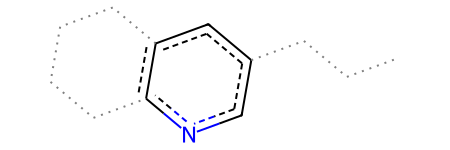

In [39]:
# prompt: de dataset filtra solo aquello elementos con Cluster_number ==1
cluster_number = 1 #### aquiiiii
# Filter the dataset DataFrame to include only elements where Cluster_number is equal to 1
filtered_df = dataset[dataset['Cluster_number'] == cluster_number]
# Now dataset_cluster_1 contains only the rows where 'Cluster_number' is 1
#filtered_df
comparison_image = draw_multiple_mcs(filtered_df.SMILES)

if comparison_image:
  comparison_image
else:
    print("MCS not found or invalid SMILES provided")


# prompt: guarda en una variable la estructura que se forma del mcs

mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(filtered_df.SMILES)
mcs_structure = mcs_mol
#mcs_structure
# prompt: guarda en una variable la estructura que se forma del mcs

mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(filtered_df.SMILES)
mcs_structure = mcs_mol
mcs_structure

In [40]:
filtered_df.head()

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,Structure,Molecule ChEMBL ID,pChEMBL Value,Molecule Name,Cluster_number
9,0.038102,638.884,7.00050,48,14,104.90,6,5,1,Nc1ccc2c(c1)c(-c1ccccc1)[n+](CCCNCCCNCCCNc1c3c...,<rdkit.Chem.rdchem.Mol object at 0x79c124e81d20>,CHEMBL179455,8.81,NaN,1
27,0.706488,198.269,2.69580,15,0,38.91,2,1,1,Nc1c2c(nc3ccccc13)CCCC2,<rdkit.Chem.rdchem.Mol object at 0x79c124e82e30>,CHEMBL95,6.75,TACRINE,1
58,0.653235,310.485,5.80432,23,7,24.92,2,1,1,CCCCCCCNc1c2c(nc3cc(C)ccc13)CCCC2,<rdkit.Chem.rdchem.Mol object at 0x79c124e83e60>,CHEMBL61221,6.89,NaN,1
66,0.197668,578.805,6.51442,43,11,73.39,6,2,1,Cc1c(N2CCN(C)CC2)nc2ccccc2c1C(=O)NCCCCCCCNc1c2...,<rdkit.Chem.rdchem.Mol object at 0x79c124f60270>,CHEMBL195241,8.39,NaN,1
158,0.396155,341.455,5.40410,25,8,68.06,4,1,1,CCCCCCCNc1c2c(nc3cc([N+](=O)[O-])ccc13)CCCC2,<rdkit.Chem.rdchem.Mol object at 0x79c124f62ab0>,CHEMBL294525,6.53,NaN,1


<IPython.core.display.Javascript object>

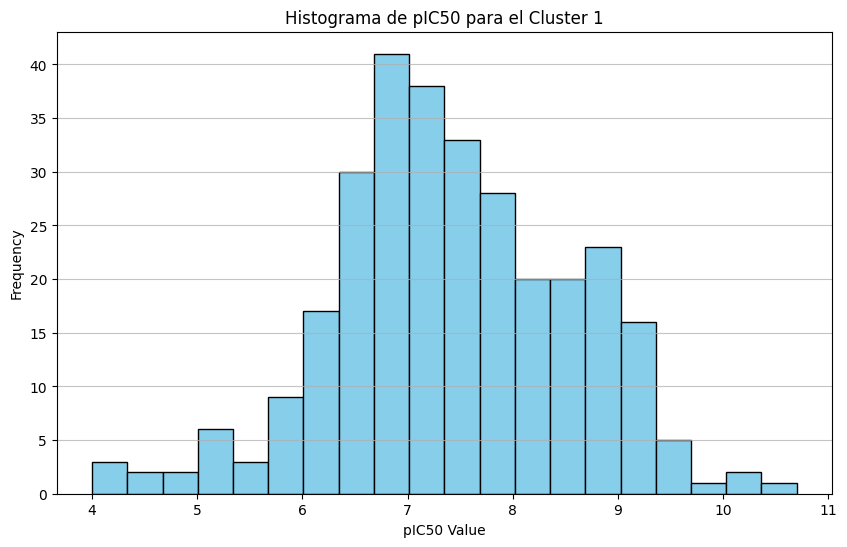

In [41]:
# prompt: has con plotly una grafica de dispersión donde en el eje y esté pChEMBL Value

fig = px.scatter(filtered_df, y='pChEMBL Value', x = 'LogP'#x=filtered_df.index,
                 #title="Relación entre Actividad y Número de Molécula",
                 #labels={"pChEMBL Value": "pChEMBL Value", "index": "Índice de Molécula"}
                 )

# Set background color to white
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#figa.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
fig.update_layout(hoverlabel_font_size=20)
#figa.update_layout(showlegend=False) # This line removes the legend
#figa.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size

app_marker = molplotly.add_molecules(fig=fig,df=filtered_df,
                                     smiles_col='SMILES', #title_col='Molecule ChEMBL ID', #color_col='cn',
                                     caption_cols=['Cluster_number'],
                                     fontsize=15, width=220)

# prompt: has un histograma con pic50 con filtered_df

plt.figure(figsize=(10, 6))
plt.hist(filtered_df['pChEMBL Value'], bins=20, color='skyblue', edgecolor='black')
plt.title(f'Histograma de pIC50 para el Cluster {cluster_number}')
plt.xlabel('pIC50 Value')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)


app_marker.run(port=8870)
print(mcs_structure)
plt.show()

# Espacio Químico

In [24]:
# prompt: de df filtered quédate con MolWt, LogP, RB,TPSA,HBA,HDB
data_k = filtered_df[['MolWt', 'LogP', 'RB', 'TPSA', 'HBA', 'HDB']]
# Normalizar datos
from sklearn.preprocessing import StandardScaler
data_std = StandardScaler().fit_transform(data_k)
# pca.fit
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca_results = pca.fit_transform(data_std)
#pca_results
# Seleccionar impormación complementaria
label = filtered_df[[ "SMILES", "Structure", 'Activity', 'Cluster_number', 'Molecule ChEMBL ID',        'pChEMBL Value',        'Molecule Name']]
label = label.to_numpy()
# Concatenar arrays de numpy
arr = np.concatenate((label, pca_results), axis = 1)
# Crear un nuevo dataframe
pca_dataset = pd.DataFrame(data=arr, columns = ["SMILES", "Structure", 'Activity', 'Cluster_number', 'Molecule ChEMBL ID',      'pChEMBL Value',        'Molecule Name',
                                                'component1', 'component2', 'component3']) # Removed 'component3'

#pca_dataset.head(2)

In [25]:
#Las cargas (loadings) representan los pesos o coeficientes de los PC's
loadings = []
#Inicia un bucle que itera sobre cada componente principal.
# pca.n_components se refiere al número de componentes principales calculados durante el análisis PCA.
# # pca.components_ es un atributo del objeto PCA ajustado (fit) que almacena las cargas (loadings) de todos los componentes principales.
for i in range(pca.n_components):
  loadings.append(pca.components_[i])
#pca loadings es una datafrme que relaciona los descripotres con los pesos de los PCA´s
pca_loadings = pd.DataFrame(data=loadings, columns=data_k.columns)
# Renombramos las columnas
pca_loadings = pca_loadings.rename(columns={0: "HBA", 1: "HBD", 2: "RB", 3: "LogP", 4: "TPSA", 5: "MW"})
# A pca_loadings vuelve cambia el indice qu ecomience desde uno
pca_loadings.index = range(1, len(pca_loadings) + 1)
# Obtenemos las ecuaciones de PC's
equations = {}
for index, row in pca_loadings.iterrows():
  equation = "PC{} = ".format(index)
  for col, value in row.items():
    equation += "{:.4f}*{} + ".format(value, col)
  equations["PC{}".format(index)] = equation[:-3]  # Remove the last " + "
for pc, equation in equations.items():
  print(equation)
# @title
from plotly.subplots import make_subplots
import plotly.graph_objects as go
# Crea una figura
figx = go.Figure()
# Itera sobre cada índice (PC) y agrega trazas (inforación de cada PC) al gráfico de barras
for index in pca_loadings.index:
  figx.add_trace(go.Bar(x=pca_loadings.columns, # Nombres de los descriptores
                        y=pca_loadings.loc[index],  # Valores para cada uno de los PC's
                        name=index))  # Nombre de la traza (PC)
#____________Formateo_______________
figx.update_layout(title="Contribución de los Descriptores a cada PC para el Espacio Químico",
                   xaxis_title="Descriptores",
                   yaxis_title="Weight",
                   plot_bgcolor='white',
                   paper_bgcolor='white',
                   barmode='group')  # Agrupa las barras por descriptor
#figx.show()# Muestra la figura

if figx is not None:
  print("Gráfica de barras creada correctamente.")
else:
  print("No se pudo crear la gráfica de barras.")

PC1 = 0.4869*MolWt + 0.2424*LogP + 0.3986*RB + 0.4580*TPSA + 0.4603*HBA + 0.3517*HDB
PC2 = 0.2206*MolWt + 0.6344*LogP + 0.4185*RB + -0.3461*TPSA + -0.2521*HBA + -0.4364*HDB
PC3 = -0.1171*MolWt + 0.3414*LogP + -0.0408*RB + -0.0628*TPSA + -0.5375*HBA + 0.7584*HDB
Gráfica de barras creada correctamente.


#2D

In [26]:
# prompt: repite la ultima gráfica con plotly
dato1='component1'
#dato2='Activity'
dato2='pChEMBL Value'
dato3='component2'
#_________
dato4='pChEMBL Value'
# Convert 'pChEMBL Value' to numeric, coercing errors to NaN
pca_dataset['pChEMBL Value'] = pd.to_numeric(pca_dataset['pChEMBL Value'], errors='coerce')
# Drop rows with NaN values in 'pChEMBL Value' that resulted from coercion
pca_dataset.dropna(subset=['pChEMBL Value'], inplace=True)

# Create a bubble chart using Plotly
fig_bubble = px.scatter(pca_dataset,
                        x='component1',
                        y='component2',
                        size=60*3**(0.8*pca_dataset['pChEMBL Value']),  # Use 'pChEMBL Value' for bubble size
                        color='pChEMBL Value', # Use 'pChEMBL Value' for color mapping
                        title='Gráfico de Burbujas: PC1 vs PC2 (Tamaño y Color por pChEMBL Value)',
                        labels={'component1': 'Componente Principal 1 (PC1)',
                                'component2': 'Componente Principal 2 (PC2)',
                                'pChEMBL Value': 'pChEMBL Value'},
                        color_continuous_scale='viridis',
                        height=600)

# Update layout for better appearance
fig_bubble.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_bubble.update_xaxes(showgrid=True, gridcolor='lightgrey')
fig_bubble.update_yaxes(showgrid=True, gridcolor='lightgrey')


# Set background color to white
fig_bubble.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#figa.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
fig_bubble.update_layout(hoverlabel_font_size=20)
#figa.update_layout(showlegend=False) # This line removes the legend
#figa.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
fig_bubble.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
#fig_bubble.update_traces(marker=dict(size=12)) # Increase marker size
# Remove grid lines
fig_bubble.update_xaxes(showgrid=False)
fig_bubble.update_yaxes(showgrid=False)
# Show the Plotly figure
#fig_bubble.show()

app_marker = molplotly.add_molecules(fig=fig_bubble,
                                     #_____________dataframe___________________
                                     df=pca_dataset,
                                     #__________________________________________
                                     smiles_col='SMILES',
#                                    title_col='Cmpd',
                                     #_____________color_________________________
                                     #color_col='G',
                                     #color_col=dato2,
                                     #_________________________________________
                                    fontsize=20, width=350,
                                     caption_cols=[dato2],
                                     show_coords=False)
app_marker.run(port=8061)
#fig_pca.show()
figx.update_layout(width=800, height=250)
figx.show()

<IPython.core.display.Javascript object>

In [27]:
import plotly.express as px
from textwrap import wrap

named_colorscales = px.colors.named_colorscales()
print("\n".join(wrap("".join('{:<12}'.format(c) for c in named_colorscales), 96)))

aggrnyl     agsunset    blackbody   bluered     blues       blugrn      bluyl       brwnyl
bugn        bupu        burg        burgyl      cividis     darkmint    electric    emrld
gnbu        greens      greys       hot         inferno     jet         magenta     magma
mint        orrd        oranges     oryel       peach       pinkyl      plasma      plotly3
pubu        pubugn      purd        purp        purples     purpor      rainbow     rdbu
rdpu        redor       reds        sunset      sunsetdark  teal        tealgrn     turbo
viridis     ylgn        ylgnbu      ylorbr      ylorrd      algae       amp         deep
dense       gray        haline      ice         matter      solar       speed       tempo
thermal     turbid      armyrose    brbg        earth       fall        geyser      prgn
piyg        picnic      portland    puor        rdgy        rdylbu      rdylgn      spectral
tealrose    temps       tropic      balance     curl        delta       oxy         edge
hsv     

### 3D

Activity vs PC1 Vs PC2

In [28]:
#Grafica de dispersión en 3D Activity vs PC1 vs PC2
#________________Por si se enciman los datos_________________________________

a = pca_dataset.copy()
#a = pca_dataset[pca_dataset['fraction1'].isin([])]
#a = pca_dataset[pca_dataset['cn'].isin([6,9,#10,11,12,13])]

#________________Definimos la gráfica_______________________________________
dato1='component1'
#dato2='Activity'
dato2='component2'
dato3='component2'
#_________
dato4='pChEMBL Value'
#dato4='component3'
#__________________________________________________________________________
fig_pca = px.scatter_3d(data_frame=a,
                        #data_frame=a, #Por si se enciman los datos
                        #______coordenadas__________________________________
                        x=dato3,
                        y=dato1,
                        z=dato2,
                        #______color________________________________________
                        color='pChEMBL Value',
                        color_continuous_scale='viridis',
                        #______tamaño________________________________________
                        #size=60*3**(0.8*pca_dataset['pChEMBL Value']),
                        size='pChEMBL Value',# Use 'pChEMBL Value' for bubble size
                        #color='Activity',
                        #___________________________________________________
                        title=f'{dato2} vs {dato1} vs {dato3}',
                        width=900, height=900)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_pca.update_traces(marker=dict(size=12)) # Increase marker size
#______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig_pca,
                                     #___________dataframe__________________
                                     df=a,
                                     #df=a,
                                     #______________________________________
                                     smiles_col='SMILES',
                                     #title_col='Molecule ChEMBL ID',
                                     #____________color_____________________
                                     #color_col='Activity',
                                     #color_col='G',
                                     svg_size=200,

                                     #________________________________________
                                     show_coords=False,
                                     #caption_cols=[dato4],
                                     fontsize=15, width=210)
fig_pca.show()
app_marker.run(port=8065)
figx.show()

<IPython.core.display.Javascript object>

In [29]:
# prompt: haz un gráfico de burbuja con fig_pca en 3d

fig_pca = px.scatter_3d(data_frame=a,
                        x=dato3,
                        y=dato1,
                        z=dato2,
                        color='pChEMBL Value',
                        color_continuous_scale='viridis',
                        size=20*3**(.8*pca_dataset['pChEMBL Value']),  # Use 'pChEMBL Value' for bubble size
                        title=f'{dato2} vs {dato1} vs {dato3}',
                        width=900, height=900)

fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white")
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black')))

app_marker = molplotly.add_molecules(fig=fig_pca,
                                     df=a,
                                     smiles_col='SMILES',
                                     svg_size=200,
                                     show_coords=False,
                                     caption_cols=[dato4],
                                     fontsize=15, width=210)

#fig_pca.show()
app_marker.run(port=8765)
figx.show()

<IPython.core.display.Javascript object>

# Representación del Espacio Químico por T-SNE

In [30]:
data_std_ =  pd.DataFrame(data_std, columns=data_k.columns)
data_std_

,MolWt,LogP,RB,TPSA,HBA,HDB
0,0.088499,0.069551,0.032863,0.310134,0.112786,0.178372
1,0.363404,0.026694,-1.036458,0.127311,0.112786,0.178372
2,0.446577,0.371586,0.389304,0.127311,0.112786,0.178372
3,-0.297302,0.230478,0.032863,0.535039,0.112786,-1.079153
4,-0.090264,0.322799,0.389304,-0.618944,0.112786,-1.079153
...,...,...,...,...,...,...
136,-0.669517,-1.764507,-1.392898,0.912841,0.870063,0.178372
137,1.520163,0.050748,1.815065,1.936370,2.384617,1.435898
138,-0.090814,-0.773282,-0.323577,0.912841,0.870063,0.178372
139,-0.434755,-0.786495,-1.036458,0.310134,0.112786,0.178372


In [ ]:
# @title
## Entrenar modelo t-SNE
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import plotly.express as px
import molplotly

# Select relevant columns from the entire dataset
data_tsne = dataset[['MolWt', 'LogP', 'RB', 'TPSA', 'HBA', 'HDB']].copy()

# Scale the data
data_tsne = StandardScaler().fit_transform(data_tsne)

# Perform t-SNE
# Reduce perplexity to a value less than the number of samples if necessary
tsne = TSNE(n_components=3, verbose=1, perplexity=30, max_iter=10000, early_exaggeration=1) # Increased perplexity to a reasonable value for the full dataset
tsne_results = tsne.fit_transform(data_tsne)

# Prepare supplementary information from the entire dataset
label_cols = ["SMILES", "Structure", 'Activity', 'Cluster_number', 'Molecule ChEMBL ID', 'pChEMBL Value', 'Molecule Name']
label = dataset[label_cols].copy()
label = label.to_numpy()

# Concatenate arrays of numpy
arr = np.concatenate((label, tsne_results), axis=1)

# Create a new dataframe
tsne_dataset = pd.DataFrame(data=arr,
                            columns=label_cols + ['axis1', 'axis2', 'axis3'])

# Convert relevant columns to appropriate types (they are objects after concatenation)
tsne_dataset['Activity'] = pd.to_numeric(tsne_dataset['Activity'], errors='coerce')
tsne_dataset['Cluster_number'] = pd.to_numeric(tsne_dataset['Cluster_number'], errors='coerce')
tsne_dataset['pChEMBL Value'] = pd.to_numeric(tsne_dataset['pChEMBL Value'], errors='coerce')
tsne_dataset['axis1'] = pd.to_numeric(tsne_dataset['axis1'], errors='coerce')
tsne_dataset['axis2'] = pd.to_numeric(tsne_dataset['axis2'], errors='coerce')
tsne_dataset['axis3'] = pd.to_numeric(tsne_dataset['axis3'], errors='coerce')


# You can uncomment and adapt these lines if you have 'cn_s' and 'cn' columns in your original dataset
# tsne_dataset = tsne_dataset.sort_values(by=['cn_s'])
# tsne_dataset = tsne_dataset.drop_duplicates(subset='SMILES')


# Graficar

#_______________________________________________________________________________________________________


fig_tsne2d = px.scatter(tsne_dataset,
                      x='axis1', y='axis2',
                      color='Cluster_number', # Using Cluster_number for color
                      title='t-SNE (2D) colored by Cluster Number',
                      hover_data={'Cluster_number':True, 'Activity':True, 'pChEMBL Value':True, 'axis1': False, 'axis2': False},
                      hover_name='Molecule ChEMBL ID',
                      width=900,height=700)

# Set background color to white
fig_tsne2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne2d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne2d.update_traces(marker=dict(size=8)) # Adjusted marker size for larger dataset
fig_tsne2d.update_layout(hoverlabel_font_size=15) # Adjusted hover label font size


app_marker2d = molplotly.add_molecules(fig=fig_tsne2d,
                                       df=tsne_dataset,
                                       smiles_col='SMILES',
                                       title_col='Molecule ChEMBL ID',
                                       color_col='Cluster_number',
                                       width=350, fontsize= 15,
                                       caption_cols=['Cluster_number','pChEMBL Value'],
                                       show_coords=False
                                       )
#_________________________________________________________________________________________________________


fig_tsne3d = px.scatter_3d(tsne_dataset,
                      x='axis1', y='axis3', z='axis2',
                      color='Cluster_number', # Using Cluster_number for color
                      title='t-SNE (3D) colored by Cluster Number',
                      hover_data={'Cluster_number':True, 'Activity':True, 'pChEMBL Value':True, 'axis1': False, 'axis2': False, 'axis3':False},
                      hover_name='Molecule ChEMBL ID',
                      width=900,height=700)

# Set background color to white
fig_tsne3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne3d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne3d.update_traces(marker=dict(size=8)) # Adjusted marker size for larger dataset
fig_tsne3d.update_layout(hoverlabel_font_size=15) # Adjusted hover label font size


app_marker3d = molplotly.add_molecules(fig=fig_tsne3d,
                                       df=tsne_dataset,
                                       smiles_col='SMILES',
                                      #  title_col='Molecule ChEMBL ID',
                                       color_col='Cluster_number',
                                       svg_size=200,
                                       show_coords=False,
                                       caption_cols=['Cluster_number','pChEMBL Value'],
                                       fontsize=15, width=210)

#_____________________________________________________________________________________________________
app_marker2d.run(port=8886)
app_marker3d.run(port=8896) # Use a different port for the second app
#fig_tsne2d.show()
#fig_tsne3d.show()

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 5829 samples in 0.010s...
[t-SNE] Computed neighbors for 5829 samples in 0.713s...
[t-SNE] Computed conditional probabilities for sample 1000 / 5829
[t-SNE] Computed conditional probabilities for sample 2000 / 5829
[t-SNE] Computed conditional probabilities for sample 3000 / 5829
[t-SNE] Computed conditional probabilities for sample 4000 / 5829
[t-SNE] Computed conditional probabilities for sample 5000 / 5829
[t-SNE] Computed conditional probabilities for sample 5829 / 5829
[t-SNE] Mean sigma: 0.354655
[t-SNE] KL divergence after 250 iterations with early exaggeration: 0.789663


-----------
Este es el cluster 3
-----------


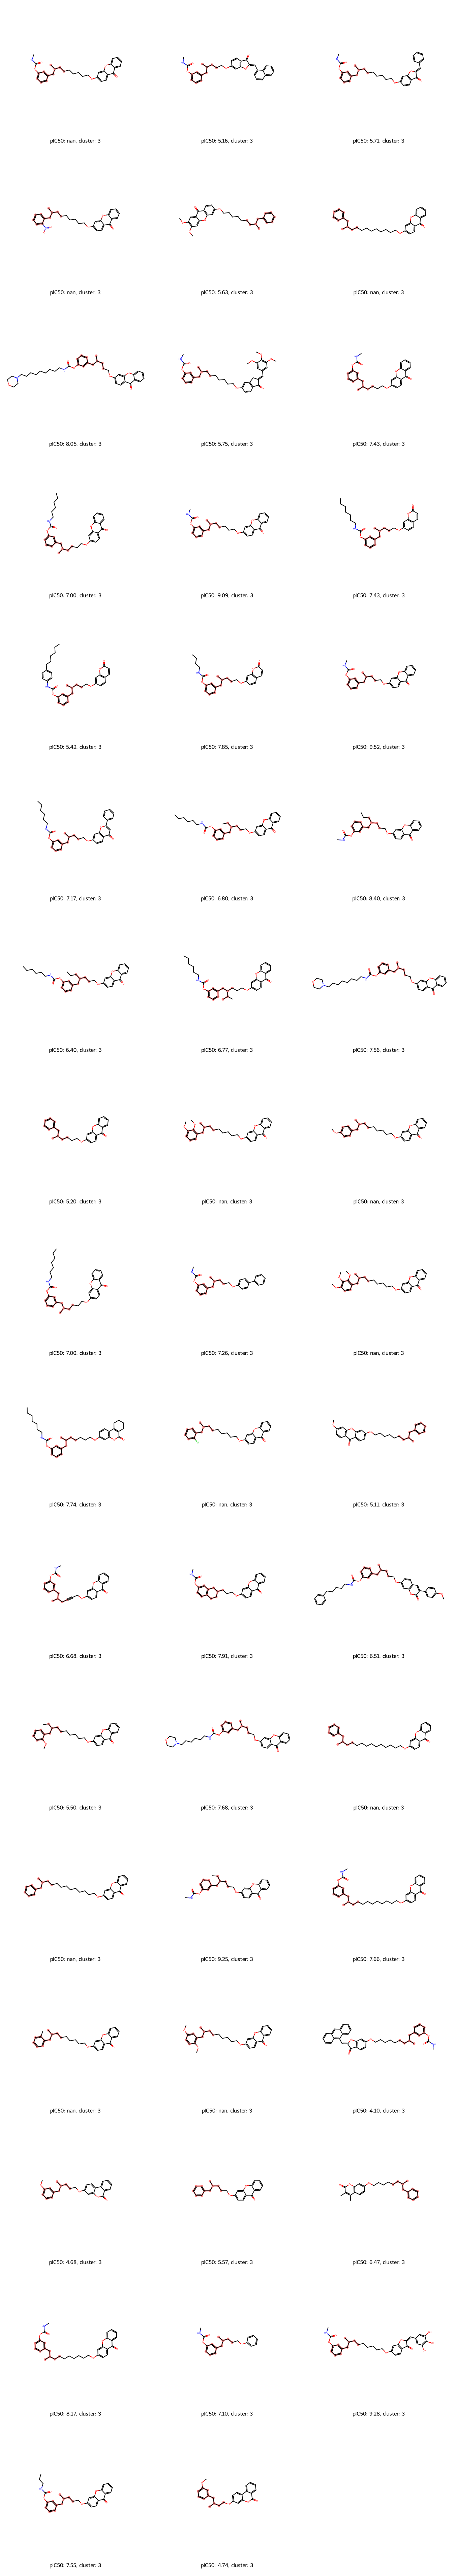

In [32]:
print('-----------')
print(f'Este es el cluster {cluster_number}')
print('-----------')
comparison_image

#todoslos MCS

In [33]:
# Get unique cluster numbers where the number of structures is >= 2
clusters = dataset.groupby('Cluster_number')['Structure'].count().reset_index()
# Filter clusters DataFrame instead of the list
clusters = clusters[clusters['Structure'] == 1]['Cluster_number'].tolist()
# Get unique cluster numbers where the number of structures is >= 2
clusters_to_process = dataset.groupby('Cluster_number')['Structure'].count().reset_index()
clusters_to_process = clusters_to_process[clusters_to_process['Structure'] >= 2]['Cluster_number'].tolist()

mcs_results = {}  # Store MCS results for each cluster

for cluster_number in clusters_to_process[:-1]: #_______AQUI
    filtered_df = dataset[dataset['Cluster_number'] == cluster_number]
    mcs_mol, _, _, success = find_mcs_multiple(filtered_df.SMILES)
    if success:
        mcs_results[cluster_number] = mcs_mol
    else:
        mcs_results[cluster_number] = None
        print(f"Could not find MCS for cluster {cluster_number}")
mcs_structure = mcs_results
#mcs_structure
# prompt: con mcs_results has un dataframe donde tengas el objeto mol relacionado con sus cluster_number
mcs_results_df = pd.DataFrame(list(mcs_results.items()), columns=['Cluster_number', 'mol'])
#mcs_results_df
# prompt: a mcs_results_df agrega la columna de cuantas moeculas tenia
mcs_results_df['molecule_count'] = mcs_results_df['Cluster_number'].map(dataset.groupby('Cluster_number')['Structure'].count().to_dict())
#mcs_results_df



In [34]:
a = Draw.MolsToGridImage([x for x in mcs_results_df["mol"]],#[:125],
                         maxMols=200,
                         legends=['Cluster ID: ' + str(x) + #'\n'
                                   ', Freq: ' + str(y) +'\n'
                                   'pMIC: ''\n'
                                   'min: ' + str(round(z,2)) + #'\n'
                                   ', max: ' + str(round(w,2)) #'\n'
                                    for x, y, z, w in zip(mcs_results_df.Cluster_number,
                                                mcs_results_df.molecule_count,
                                                dataset.groupby('Cluster_number')['pChEMBL Value'].min(), # Changed to dataset
                                                dataset.groupby('Cluster_number')['pChEMBL Value'].max())], # Changed to dataset
                          subImgSize=(350,450), molsPerRow=5)
a

In [35]:
# prompt: de dataset toma los valores donde cluster_nuiber solo aparece una vez

# Filter the dataset DataFrame to include only rows where 'Cluster_number' appears only once.
cluster_counts = dataset['Cluster_number'].value_counts()
single_occurrence_clusters = cluster_counts[cluster_counts == 1].index
dataset_filtered = dataset[dataset['Cluster_number'].isin(single_occurrence_clusters)]
#dataset_filtered
# prompt: ordena  de manera crecienta con respecto a la columna Cluster_nummber a dataset_filtered

# Sort the DataFrame by the 'Cluster_number' column in ascending order
dataset_filtered = dataset_filtered.sort_values('Cluster_number')
#dataset_filtered

In [36]:
b = Draw.MolsToGridImage([x for x in dataset_filtered["Structure"]][:125], maxMols=200,
                     legends=['Cluster ID: ' + str(x) for x in dataset_filtered.Cluster_number],
                     subImgSize=(350,350), molsPerRow=3)
#b

In [37]:
#mcs_results_df



In [38]:
# Create a single list for legends
legends = []

# Add legends for mcs_results_df
legends.extend([
  'Cluster ID: ' + str(x) +
    ', freq: ' + str(y) + '\n' +
    '´pMIC: ''\n' +
    'min : ' + str(round(z,2)) +
    ', max : ' + str(round(w,2))
    for x, y, z, w in zip(mcs_results_df.Cluster_number,
                        mcs_results_df.molecule_count,
                        dataset.groupby('Cluster_number')['pChEMBL Value'].min(),
                        dataset.groupby('Cluster_number')['pChEMBL Value'].max())
])

# Add legends for dataset_filtered
legends.extend([
    'Cluster ID: ' + str(x) + ', pMIC: ' + str(round(y,2))
    for x, y in zip(dataset_filtered.Cluster_number, dataset_filtered['pChEMBL Value'])
])

# Now use the flattened 'legends' list in MolsToGridImage
combined_image = Draw.MolsToGridImage(
    [x for x in mcs_results_df["mol"]] + [x for x in dataset_filtered["Structure"]],
    legends=legends,
    maxMols=200,
    subImgSize=(350, 350),
    molsPerRow=4
)
combined_image

# Conclusión

Hemos aprendido a calcular huellas dactilares moleculares (claves MACCS, Avalon, pares de átomos, torsiones topológicas y huellas dactilares de Morgan) usando RDKit para una sola molécula o varias moléculas. También vimos cómo calcular el coeficiente de Tanimoto y la agrupación de Taylor-Butina y el filtrado de moléculas por contenido de segmentos

<div style="background-color:lightgreen; border-style: dotted;border-color: yellow;text-align:center;color:blue;font-size:20px;border-radius: 50px;padding: 20px 20px;"><strong> Tomado originalmente de
Gashaw M. Goshu, Ph.D. in Chemistry </strong></div> https://www.youtube.com/watch?v=-oHqQBUyrQ0 , adaptado por el Dr. Erick Correa para el curso de Desarrollo de Fármacos Asistido por Computadora Laboratorio de Síntesis de Fármacos L-9, F.E.S. Zaragoza UNAM

